# Assignment 3 Time Series Weather Forecasting

**Steve Lambert**  
BA 64061 Advanced Machine Learning

This assignment uses recurrent neural networks to predict the air temperature 24 hours ahead from the previous five days of Jena weather observations. The main comparison is validation mean absolute error, where lower values are better.

## Summary

The best model was **LSTM 32 with recurrent dropout**. It reached a validation MAE of **2.31 degrees C** and a test MAE of **2.49 degrees C**. This reduced test error by **5.1%** compared with the naive forecast.

## Setup and Data

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.20.0


The dataset contains 14 weather measures recorded every 10 minutes from 2009 through 2016. I kept the chronological 50% training, 25% validation, and 25% test split used in the chapter. Only the training portion was used to calculate the normalization mean and standard deviation.

In [2]:
DATA_URL = 'https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip'
downloaded_path = Path(keras.utils.get_file(
    'jena_climate_2009_2016.csv.zip', origin=DATA_URL, extract=True))
if downloaded_path.is_dir():
    csv_path = next(downloaded_path.rglob('jena_climate_2009_2016.csv'))
else:
    csv_path = downloaded_path.with_suffix('')
weather = pd.read_csv(csv_path)
temperature = weather.iloc[:, 2].to_numpy(dtype='float32')
raw_data = weather.iloc[:, 1:].to_numpy(dtype='float32')

num_train_samples = int(0.50 * len(raw_data))
num_val_samples = int(0.25 * len(raw_data))
num_test_samples = len(raw_data) - num_train_samples - num_val_samples
train_mean = raw_data[:num_train_samples].mean(axis=0)
train_std = raw_data[:num_train_samples].std(axis=0)
normalized_data = (raw_data - train_mean) / train_std

print('Rows:', len(raw_data))
print('Training rows:', num_train_samples)
print('Validation rows:', num_val_samples)
print('Test rows:', num_test_samples)

Rows: 420451
Training rows: 210225
Validation rows: 105112
Test rows: 105114


## Time Series Samples and Baseline

In [3]:
sampling_rate = 6
sequence_length = 120
delay = sampling_rate * (sequence_length + 24 - 1)
batch_size = 256

common = dict(
    data=normalized_data[:-delay], targets=temperature[delay:],
    sampling_rate=sampling_rate, sequence_length=sequence_length,
    batch_size=batch_size)
train_dataset = keras.utils.timeseries_dataset_from_array(
    **common, shuffle=True, seed=SEED, start_index=0,
    end_index=num_train_samples)
val_dataset = keras.utils.timeseries_dataset_from_array(
    **common, shuffle=False, start_index=num_train_samples,
    end_index=num_train_samples + num_val_samples)
test_dataset = keras.utils.timeseries_dataset_from_array(
    **common, shuffle=False, start_index=num_train_samples + num_val_samples)

def naive_mae(dataset):
    total_error = 0.0
    samples_seen = 0
    for samples, targets in dataset:
        predictions = samples[:, -1, 1] * train_std[1] + train_mean[1]
        total_error += float(tf.reduce_sum(tf.abs(predictions - targets)))
        samples_seen += int(samples.shape[0])
    return total_error / samples_seen

print(f'Naive validation MAE: {naive_mae(val_dataset):.2f} degrees C')
print(f'Naive test MAE: {naive_mae(test_dataset):.2f} degrees C')

Naive validation MAE: 2.44 degrees C
Naive test MAE: 2.62 degrees C


## Models

I changed the recurrent unit type, number of units, dropout, number of recurrent layers, and the use of a Conv1D layer. Every model used RMSprop, mean squared error as the loss, and MAE as the reported metric. Early stopping used validation MAE.

In [4]:
def make_model(name, input_shape):
    inputs = keras.Input(shape=input_shape)
    if name == 'GRU 16 units':
        x = layers.GRU(16)(inputs)
    elif name == 'GRU 32 units':
        x = layers.GRU(32)(inputs)
    elif name == 'LSTM 32 units':
        x = layers.LSTM(32)(inputs)
    elif name == 'LSTM 32 with recurrent dropout':
        x = layers.LSTM(32, recurrent_dropout=0.25)(inputs)
        x = layers.Dropout(0.50)(x)
    elif name == 'Stacked GRU 32 and 16':
        x = layers.GRU(32, dropout=0.20, return_sequences=True)(inputs)
        x = layers.GRU(16, dropout=0.20)(x)
        x = layers.Dropout(0.30)(x)
    elif name == 'Conv1D plus GRU 32':
        x = layers.Conv1D(32, 5, activation='relu')(inputs)
        x = layers.MaxPooling1D(2)(x)
        x = layers.GRU(32)(x)
    else:
        raise ValueError(name)
    return keras.Model(inputs, layers.Dense(1)(x), name=name.replace(' ', '_'))

The following cell contains the training loop. The saved notebook loads the completed results so it can be reviewed without retraining all six models. Set `RUN_TRAINING` to `True` to repeat the full experiment.

In [5]:
RUN_TRAINING = False
model_names = [
    'GRU 16 units', 'GRU 32 units', 'LSTM 32 units',
    'LSTM 32 with recurrent dropout', 'Stacked GRU 32 and 16',
    'Conv1D plus GRU 32']

if RUN_TRAINING:
    input_shape = (sequence_length, raw_data.shape[-1])
    experiment_rows = []
    for model_name in model_names:
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = make_model(model_name, input_shape)
        model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])
        checkpoint = model_name.lower().replace(' ', '_') + '.keras'
        callbacks = [
            keras.callbacks.ModelCheckpoint(
                checkpoint, monitor='val_mae', mode='min', save_best_only=True),
            keras.callbacks.EarlyStopping(
                monitor='val_mae', mode='min', patience=2, min_delta=0.01)]
        history = model.fit(
            train_dataset, epochs=12, validation_data=val_dataset,
            callbacks=callbacks, verbose=2)
        best_epoch = int(np.argmin(history.history['val_mae']) + 1)
        experiment_rows.append({
            'model': model_name, 'best_epoch': best_epoch,
            'best_validation_mae': min(history.history['val_mae'])})
    pd.DataFrame(experiment_rows).to_csv('new_experiment_results.csv', index=False)
else:
    print('Using the saved results from the completed training run.')

Using the saved results from the completed training run.


## Results

In [6]:
results = pd.read_csv('experiment_results.csv')
table = results[['model', 'architecture', 'units', 'dropout',
                 'best_epoch', 'best_validation_mae', 'test_mae']].copy()
table.columns = ['Model', 'Architecture', 'Units', 'Dropout',
                 'Best epoch', 'Validation MAE', 'Test MAE']
table['Validation MAE'] = table['Validation MAE'].map(lambda x: f'{x:.2f}')
table['Test MAE'] = table['Test MAE'].map(lambda x: '' if pd.isna(x) else f'{x:.2f}')
table.fillna('', inplace=True)
table

Model,Architecture,Units,Dropout,Best epoch,Validation MAE,Test MAE
Naive baseline,Current temperature,,,0,2.44,2.62
GRU 16 units,1 GRU layer,16,,2,2.39,
GRU 32 units,1 GRU layer,32,,2,2.42,
LSTM 32 units,1 LSTM layer,32,,1,2.46,
LSTM 32 with recurrent dropout,1 LSTM layer,32,"0.25 recurrent, 0.50 output",5,2.31,2.49
Stacked GRU 32 and 16,2 GRU layers,"32, 16","0.20 layer, 0.30 output",4,2.35,
Conv1D plus GRU 32,Conv1D + GRU,"32 filters, 32 GRU",,1,2.42,


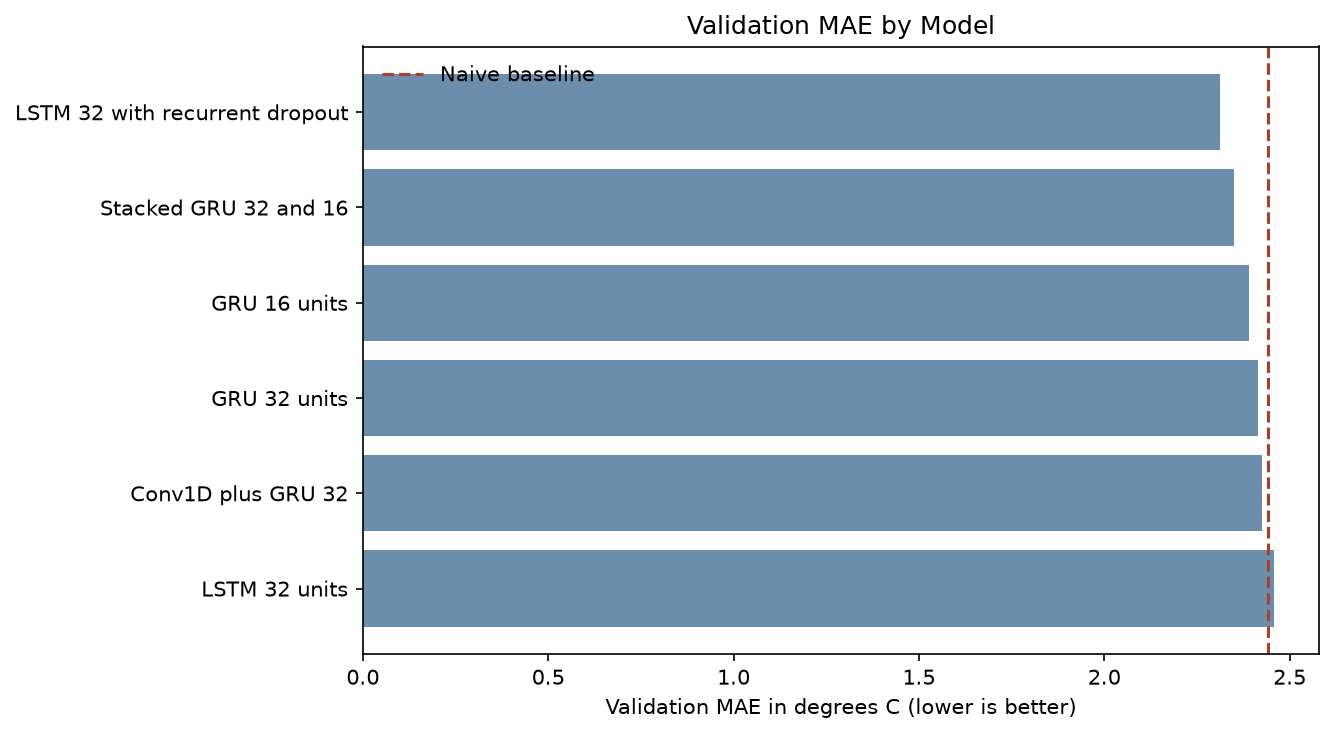

In [7]:
model_results = results[results['model'] != 'Naive baseline'].sort_values(
    'best_validation_mae')
baseline_mae = results.loc[results['model'] == 'Naive baseline',
                           'best_validation_mae'].iloc[0]
plt.figure(figsize=(9, 5))
plt.barh(model_results['model'], model_results['best_validation_mae'],
         color='#6C8EAD')
plt.axvline(baseline_mae, color='#A64132', linestyle='--', label='Naive baseline')
plt.gca().invert_yaxis()
plt.xlabel('Validation MAE in degrees C (lower is better)')
plt.title('Validation MAE by Model')
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

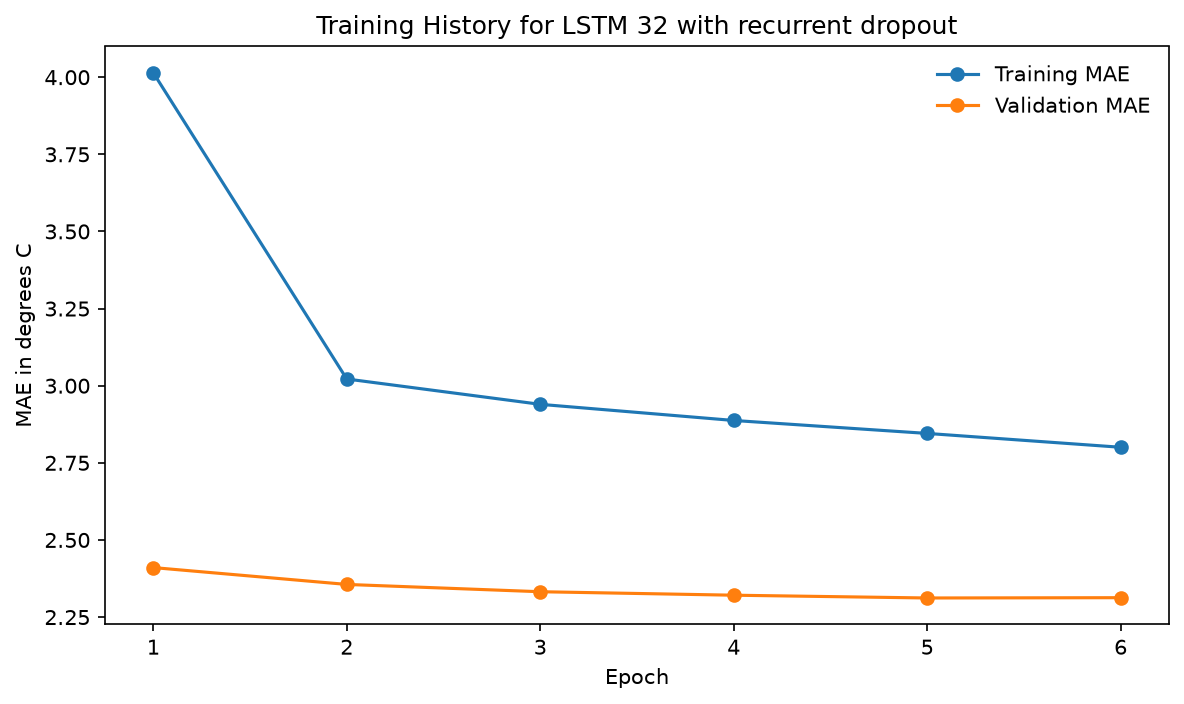

In [8]:
with open('training_histories.json', encoding='utf-8') as file:
    histories = json.load(file)
winner_name = results.loc[
    (results['model'] != 'Naive baseline') & results['test_mae'].notna(),
    'model'].iloc[0]
winner_history = histories[winner_name]
epochs = range(1, len(winner_history['mae']) + 1)
plt.figure(figsize=(8, 4.8))
plt.plot(epochs, winner_history['mae'], marker='o', label='Training MAE')
plt.plot(epochs, winner_history['val_mae'], marker='o', label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE in degrees C')
plt.title(f'Training History for {winner_name}')
plt.xticks(list(epochs))
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Conclusions

The 16-unit GRU improved on the naive validation MAE, but increasing the GRU to 32 units did not help. The plain 32-unit LSTM also performed worse than the smaller GRU. The best result came from adding recurrent dropout to the 32-unit LSTM. Its validation MAE of **2.31 degrees C** was 5.3% lower than the naive baseline. The stacked GRU was the second-best model, while the Conv1D plus GRU model did not improve the result.

After selecting the regularized LSTM from validation results, I evaluated it once on the test set. The test MAE was **2.49 degrees C**, compared with **2.62 degrees C** for the naive forecast. The experiment shows that dropout improved generalization more than simply adding units or layers.